In [277]:
# This has to be run in the allensdk environment

In [1]:
from allensdk.core.nwb_data_set import \
    NwbDataSet
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import os
import pandas as pd
from scipy.signal import find_peaks
data_path = '/Users/katharinaduecker/Documents/projects_brown/hnn-tuning/data/interneuron'
nwb_file = '571709765_ephys.nwb'
nwb = NwbDataSet(os.path.join(data_path,nwb_file))


ImportError: dlopen(/Users/katharinaduecker/miniconda3/envs/allensdk/lib/python3.11/site-packages/scipy/linalg/_fblas.cpython-311-darwin.so, 0x0002): Library not loaded: @rpath/libgfortran.5.dylib
  Referenced from: <C435405B-BFF1-399F-A1EC-BD43418F546A> /Users/katharinaduecker/miniconda3/envs/allensdk/lib/libopenblas.0.dylib
  Reason: tried: '/Users/katharinaduecker/miniconda3/envs/allensdk/lib/libgfortran.5.dylib' (duplicate LC_RPATH '@loader_path'), '/Users/katharinaduecker/miniconda3/envs/allensdk/lib/libgfortran.5.dylib' (duplicate LC_RPATH '@loader_path'), '/Users/katharinaduecker/miniconda3/envs/allensdk/lib/python3.11/site-packages/scipy/linalg/../../../../libgfortran.5.dylib' (duplicate LC_RPATH '@loader_path'), '/Users/katharinaduecker/miniconda3/envs/allensdk/lib/python3.11/site-packages/scipy/linalg/../../../../libgfortran.5.dylib' (duplicate LC_RPATH '@loader_path'), '/Users/katharinaduecker/miniconda3/envs/allensdk/bin/../lib/libgfortran.5.dylib' (duplicate LC_RPATH '@loa

In [8]:
df = pd.read_csv(os.path.join('/Users/katharinaduecker/Documents/projects_brown/hnn-tuning/data','cell_types_specimen_details.csv'))
df

,line_name,specimen__id,specimen__name,specimen__hemisphere,structure__id,structure__name,structure__acronym,structure_parent__id,structure_parent__acronym,structure__layer,...,ephys_thumb_path,ephys_inst_thresh_thumb_path,donor__age,donor__sex,donor__disease_state,donor__race,donor__years_of_seizure_history,donor__species,donor__id,donor__name
0,NaN,525011903,H16.03.003.01.14.02,right,12113,"""frontal lobe""",FroL,12113,FroL,3,...,/api/v2/well_known_file_download/529903140,/api/v2/well_known_file_download/529903142,25 yrs,Male,epilepsy,White or Caucasian,9.0,Homo Sapiens,524848408,H16.03.003
1,Oxtr-T2A-Cre,565871768,Oxtr-2A-Cre;Ai14-293837.03.01.02,left,778,"""Primary visual area, layer 5""",VISp5,385,VISp,5,...,/api/v2/well_known_file_download/566738214,/api/v2/well_known_file_download/566738219,NaN,NaN,NaN,NaN,NaN,Mus musculus,563340157,Oxtr-T2A-Cre;Ai14-293837
2,Pvalb-IRES-Cre,469801138,Pvalb-IRES-Cre;Ai14-170927.05.02.01,right,721,"""Primary visual area, layer 4""",VISp4,385,VISp,4,...,/api/v2/well_known_file_download/487618917,/api/v2/well_known_file_download/491380580,NaN,NaN,NaN,NaN,NaN,Mus musculus,319194354,Pvalb-IRES-Cre;Ai14(IVSCC)-170927
3,NaN,528642047,H16.06.009.01.02.06.05,left,12141,"""middle temporal gyrus""",MTG,12141,MTG,5,...,/api/v2/well_known_file_download/660970973,/api/v2/well_known_file_download/660970975,48 yrs,Female,epilepsy,unknown,33.0,Homo Sapiens,528574320,H16.06.009
4,Slc32a1-T2A-FlpO|Vipr2-IRES2-Cre,605889373,Vipr2-IRES2-Cre;Slc32a1-T2A-FlpO;Ai65-337419.0...,right,821,"""Primary visual area, layer 2/3""",VISp2/3,385,VISp,02-Mar,...,/api/v2/well_known_file_download/657612184,/api/v2/well_known_file_download/657612186,NaN,NaN,NaN,NaN,NaN,Mus musculus,605622695,Vipr2-IRES2-Cre;Slc32a1-T2A-FlpO;Ai65-337419
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2328,NaN,601958555,H17.03.010.11.13.06,left,12141,"""middle temporal gyrus""",MTG,12141,MTG,4,...,/api/v2/well_known_file_download/606116041,/api/v2/well_known_file_download/606116043,38 yrs,Female,epilepsy,unknown,11.0,Homo Sapiens,601901227,H17.03.010
2329,Rorb-IRES2-Cre,488473535,Rorb-IRES2-Cre-D;Ai14-212867.03.01.01,left,821,"""Primary visual area, layer 2/3""",VISp2/3,385,VISp,02-Mar,...,/api/v2/well_known_file_download/488474970,/api/v2/well_known_file_download/491376689,NaN,NaN,NaN,NaN,NaN,Mus musculus,487607572,Rorb-IRES2-Cre-D;Ai14-212867
2330,Rorb-IRES2-Cre,467003163,Rorb-IRES2-Cre-D;Ai14-172652.02.02.01,right,721,"""Primary visual area, layer 4""",VISp4,385,VISp,4,...,/api/v2/well_known_file_download/487623212,/api/v2/well_known_file_download/491378303,NaN,NaN,NaN,NaN,NaN,Mus musculus,322489498,Rorb-IRES2-Cre-D;Ai14(IVSCC)-172652
2331,Pvalb-IRES-Cre,572609946,Pvalb-IRES-Cre;Ai14-301945.04.02.01,right,721,"""Primary visual area, layer 4""",VISp4,385,VISp,4,...,/api/v2/well_known_file_download/575795570,/api/v2/well_known_file_download/575795572,NaN,NaN,NaN,NaN,NaN,Mus musculus,570930952,Pvalb-IRES-Cre;Ai14-301945


In [3]:
# get sweep index of interest

sweeps = nwb.get_experiment_sweep_numbers()
sweeps_meta = dict()
for sweep in sweeps:
    sweeps_meta[sweep] = nwb.get_sweep_metadata(sweep)

sweeps_df = pd.DataFrame.from_dict(sweeps_meta, orient='index')

sweeps_long = sweeps_df[(sweeps_df['aibs_stimulus_name'] == b'Long Square') & (sweeps_df['aibs_stimulus_amplitude_pa'] >0)]

NameError: name 'nwb' is not defined

## FR slope

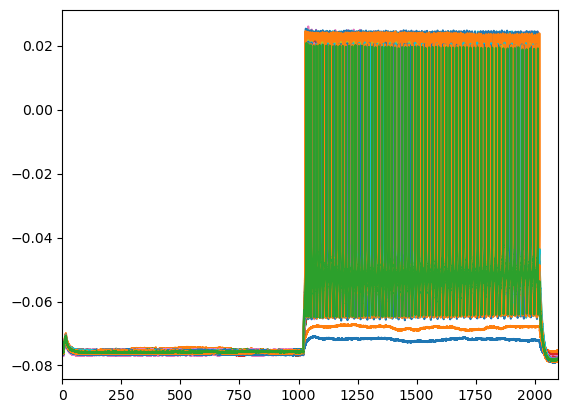

In [280]:
# get voltage trace
FR_longsqu = dict()

for i in sweeps_long.index:
    sweep = nwb.get_sweep(i)
    FR_longsqu[i] = dict()
    FR_longsqu[i]['amplitude'] = sweeps_long['aibs_stimulus_amplitude_pa'][i]
    # read v and t as numpy arrays
    v = sweep['response']
    pk = find_peaks(v,height=0)
    FR_longsqu[i]['FR'] = len(pk[0])
    dt = 1.0e3 / sweep['sampling_rate']
    num_samples = len(v)
    t = np.arange(num_samples) * dt

    plt.plot(t,v)
    plt.xlim([0,2100])

In [281]:
df_FR = pd.DataFrame.from_dict(FR_longsqu, orient='index')

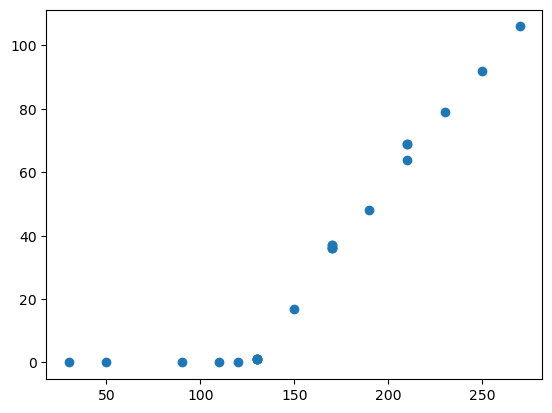

In [282]:
plt.plot(df_FR.amplitude.values, df_FR.FR.values,'o')

FR_slope = df_FR.amplitude.values[df_FR.FR.values>1]/df_FR.FR.values[df_FR.FR.values>1]
max_FR_slope = np.max(FR_slope)

## Input resistance

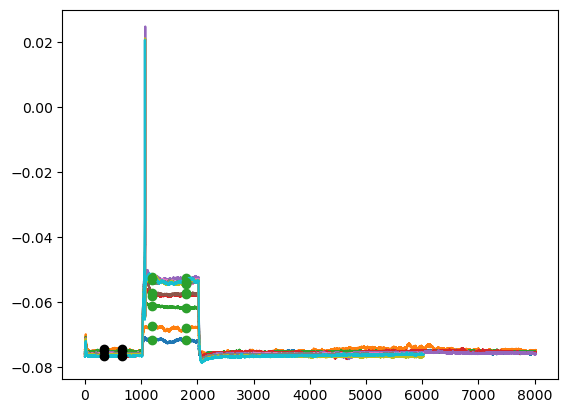

In [283]:
# get voltage trace
inp_res = dict()

for i in sweeps_long.index:

    sweep = nwb.get_sweep(i)
    
    # read v and t as numpy arrays
    v = sweep['response']

    pk = find_peaks(v,height=0)

    if len(pk[0])<=1:
        inp_res[i] = dict()
        inp_res[i]['amplitude'] = sweeps_long['aibs_stimulus_amplitude_pa'][i]
        dt = 1.0e3 / sweep['sampling_rate']
        num_samples = len(v)
        t = np.arange(num_samples) * dt
        t1 = int(sr*1.2)
        t2 = int(sr*1.8)

        sr = int(sweep['sampling_rate'])
        dV = np.mean(v[t1:t2])-np.mean(v[int(sr/3):int(sr/1.5)])
        inp_res[i]['Rm'] = dV/inp_res[i]['amplitude']

        plt.plot(t,v)

        plt.plot(t[int(sr/3)],v[int(sr/3)],'o',color='k')
        plt.plot(t[int(sr/1.5)],v[int(sr/1.5)],'o',color='k')
        plt.plot(t[t1],v[t1],'o',color='tab:green')
        plt.plot(t[t2],v[t2],'o',color='tab:green')

inp_res = pd.DataFrame.from_dict(inp_res, orient='index')
m_inp_res = np.mean(inp_res['Rm'])

0.00015876164722558502

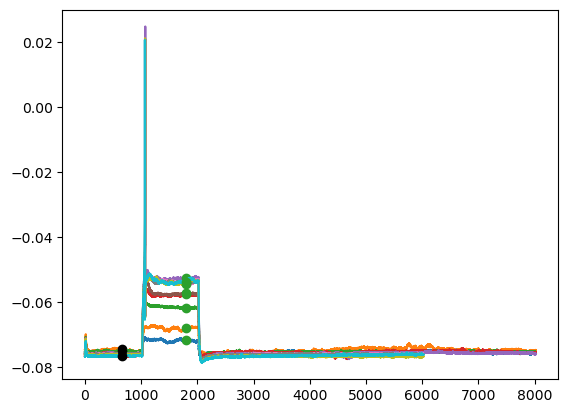

In [298]:
# get voltage trace
steady_res = dict()

for i in sweeps_long.index:

    sweep = nwb.get_sweep(i)
    
    # read v and t as numpy arrays
    v = sweep['response']

    pk = find_peaks(v,height=0)

    if len(pk[0])<=1:
        steady_res[i] = dict()
        steady_res[i]['amplitude'] = sweeps_long['aibs_stimulus_amplitude_pa'][i]
        dt = 1.0e3 / sweep['sampling_rate']
        num_samples = len(v)
        t = np.arange(num_samples) * dt
        t1 = int(sr*1.2)
        t2 = int(sr*1.8)

        sr = int(sweep['sampling_rate'])
        dV = np.mean(v[t2])-np.mean(v[int(sr/1.5)])
        steady_res[i]['Rm'] = dV/steady_res[i]['amplitude']

        plt.plot(t,v)

        plt.plot(t[int(sr/1.5)],v[int(sr/1.5)],'o',color='k')
        plt.plot(t[t2],v[t2],'o',color='tab:green')

steady_res = pd.DataFrame.from_dict(steady_res, orient='index')
m_inp_res = np.mean(steady_res['Rm'])
m_inp_res

## Sag ratio

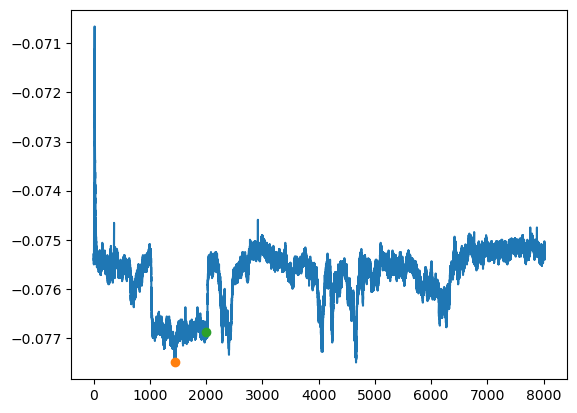

In [285]:
sweeps_hyperpol = sweeps_df[(sweeps_df['aibs_stimulus_name'] == b'Long Square') & (sweeps_df['aibs_stimulus_amplitude_pa'] < 0)]
sag_ratio = dict()

for i in sweeps_hyperpol.index:

    sweep = nwb.get_sweep(i)
    sag_ratio[i] = dict()
    v = sweep['response']
    dt = 1.0e3 / sweep['sampling_rate']
    num_samples = len(v)
    t = np.arange(num_samples) * dt


    peak_hyperpol = np.min(v)

    t_index = np.argmin(np.abs(t-2000))
    steady_state = v[t_index]
    sag_ratio[i]['amplitude'] = sweeps_hyperpol['aibs_stimulus_amplitude_pa'][i]
    sag_ratio[i]['sag_ratio'] = peak_hyperpol/steady_state

plt.plot(t,v)
plt.plot(t[np.argmin(v)],peak_hyperpol,'o')
plt.plot(t[t_index],v[t_index],'o')


In [286]:
df_sag_ratio = pd.DataFrame.from_dict(sag_ratio, orient='index')

In [287]:
df_sag_ratio

,amplitude,sag_ratio
23,-110.000002,1.026242
24,-90.000001,1.022980
25,-69.999999,1.023014
27,-29.999999,1.007911
28,-10.000000,1.008130


In [288]:
sweeps_short = sweeps_df[(sweeps_df['aibs_stimulus_name'] == b'Short Square') & (sweeps_df['aibs_stimulus_amplitude_pa'] >0)]

In [289]:
# get voltage trace

crit_thresh = dict()
for i in sweeps_short.index:
    sweep = nwb.get_sweep(i)
    # read v and t as numpy arrays
    v = sweep['response']
    crit_thresh[i] = dict()
    crit_thresh[i]['ampl'] = sweeps_short['aibs_stimulus_amplitude_pa'][i]
    sr = int(sweep['sampling_rate'])
    dt = 1.0e3 / sweep['sampling_rate']
    num_samples = len(v)
    t = np.arange(num_samples) * dt
    ap, properties = find_peaks(v, height=0,width=0)

    
    if len(ap)>0:
        crit_thresh[i]['spike'] = 1

    else:
        crit_thresh[i]['spike'] = 0


In [290]:
crit_thresh = pd.DataFrame.from_dict(crit_thresh, orient='index')

In [291]:
high_noap = crit_thresh[crit_thresh['ampl'] == np.max(crit_thresh['ampl'][crit_thresh['spike']==0])].index


In [292]:
low_ap = crit_thresh[crit_thresh['ampl'] == np.min(crit_thresh['ampl'][crit_thresh['spike']==1])].index

{'peak_heights': array([], dtype=float64), 'prominences': array([], dtype=float64), 'left_bases': array([], dtype=int64), 'right_bases': array([], dtype=int64), 'widths': array([], dtype=float64), 'width_heights': array([], dtype=float64), 'left_ips': array([], dtype=float64), 'right_ips': array([], dtype=float64)}


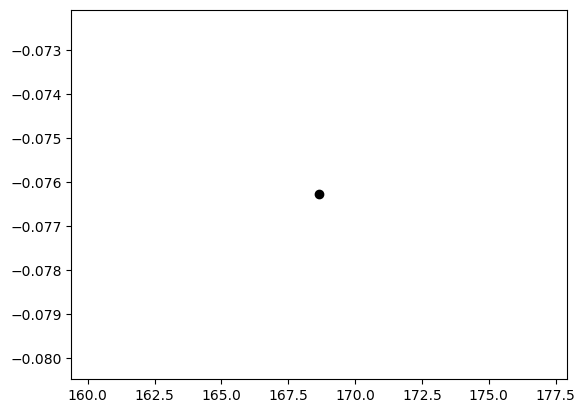

In [293]:
        print(properties)
        start_ap = np.argmax(np.gradient(np.gradient(v,t),t))
        plt.plot(t[start_ap],v[start_ap],'o',color='k')

    

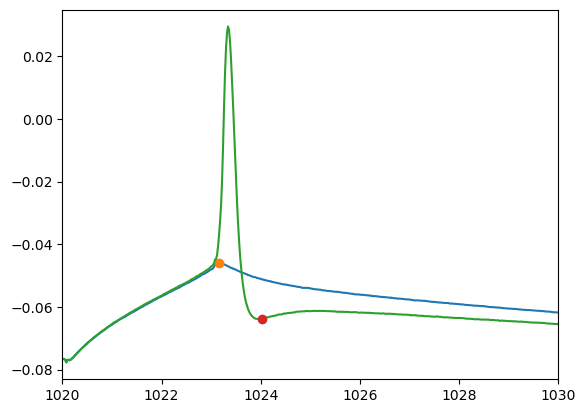

In [294]:
sweep = nwb.get_sweep(high_noap[0])
# read v and t as numpy arrays
v_noap = sweep['response']
sr = int(sweep['sampling_rate'])
dt = 1.0e3 / sweep['sampling_rate']
num_samples = len(v_noap)
t = np.arange(num_samples) * dt
pk = find_peaks(v_noap,prominence=0.01)

sweep = nwb.get_sweep(low_ap[0])
v_ap = sweep['response']
pk_down = find_peaks(-v_ap[int(pk[0]):],prominence=0.002,distance=4)

plt.plot(t,v_noap)
plt.plot(t[pk[0]],v_noap[pk[0]],'o')
plt.plot(t,v_ap)
plt.plot(t[int(pk_down[0]+pk[0])],v_ap[int(pk_down[0]+pk[0])],'o')

plt.xlim([1020,1030])
ap_dur = t[int(pk_down[0]+pk[0])] - t[pk[0]]

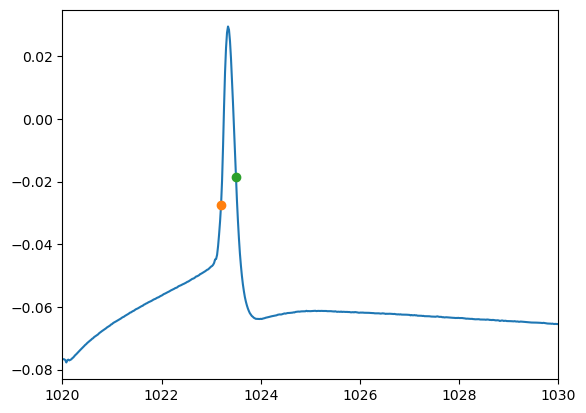

In [295]:
pk = find_peaks(v_ap,height=0,width=1)
plt.plot(t,v_ap)
plt.plot(t[int(pk[1]['left_ips'])],v_ap[int(pk[1]['left_ips'])],'o')
plt.plot(t[int(pk[1]['right_ips'])],v_ap[int(pk[1]['right_ips'])],'o')

plt.xlim([1020,1030])

spike_dur = t[int(pk[1]['right_ips'])] - t[int(pk[1]['left_ips'])]